In [1]:
import sys

In [2]:
print(sys.executable)

c:\work\blog\chb.github.io\.venv\Scripts\python.exe


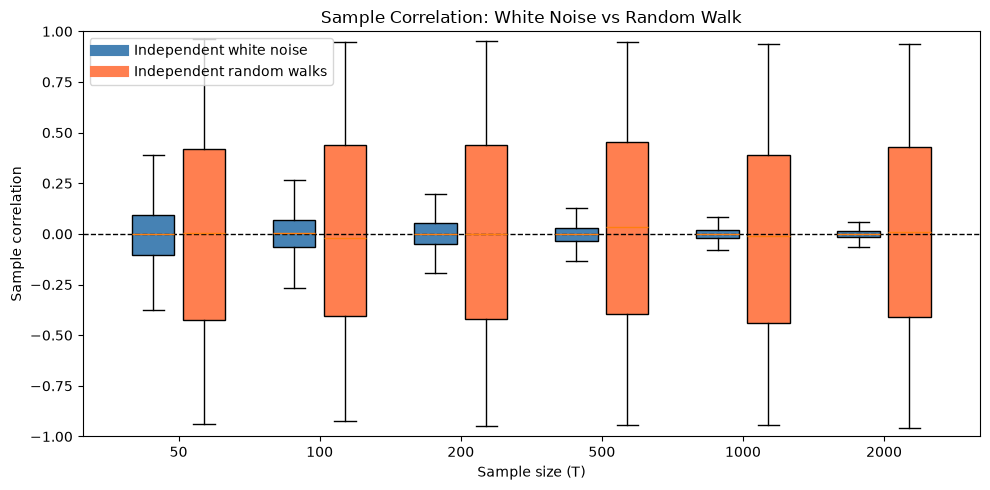

In [3]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2240082)

B = 1000
T_list = [50, 100, 200, 500, 1000, 2000]


def sample_corr(x, y):
    """각 반복실험의 표본상관계수를 계산."""
    xc = x - x.mean(axis=1, keepdims=True)
    yc = y - y.mean(axis=1, keepdims=True)

    numerator = np.sum(xc * yc, axis=1)
    denominator = np.sqrt(
        np.sum(xc**2, axis=1) * np.sum(yc**2, axis=1)
    )
    return numerator / denominator


corr_white = []
corr_rw = []

for T in T_list:
    # 서로 독립인 정규 백색잡음
    eps = rng.standard_normal((B, T))
    eta = rng.standard_normal((B, T))

    # 백색잡음의 표본상관계수
    corr_white.append(sample_corr(eps, eta))

    # 누적합으로 독립 랜덤워크 생성
    x_rw = np.cumsum(eps, axis=1)
    y_rw = np.cumsum(eta, axis=1)

    corr_rw.append(sample_corr(x_rw, y_rw))


fig, ax = plt.subplots(figsize=(10, 5))

positions = np.arange(len(T_list))
offset = 0.18

bp1 = ax.boxplot(
    corr_white,
    positions=positions - offset,
    widths=0.3,
    patch_artist=True,
    showfliers=False,
)

bp2 = ax.boxplot(
    corr_rw,
    positions=positions + offset,
    widths=0.3,
    patch_artist=True,
    showfliers=False,
)

for patch in bp1["boxes"]:
    patch.set_facecolor("steelblue")

for patch in bp2["boxes"]:
    patch.set_facecolor("coral")

ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set_xticks(positions)
ax.set_xticklabels(T_list)
ax.set_xlabel("Sample size (T)")
ax.set_ylabel("Sample correlation")
ax.set_title("Sample Correlation: White Noise vs Random Walk")
ax.set_ylim(-1, 1)

ax.plot([], [], color="steelblue", linewidth=8,
        label="Independent white noise")
ax.plot([], [], color="coral", linewidth=8,
        label="Independent random walks")
ax.legend()

plt.tight_layout()
plt.show()


White noise: 5.80%
Random walk: 82.74%


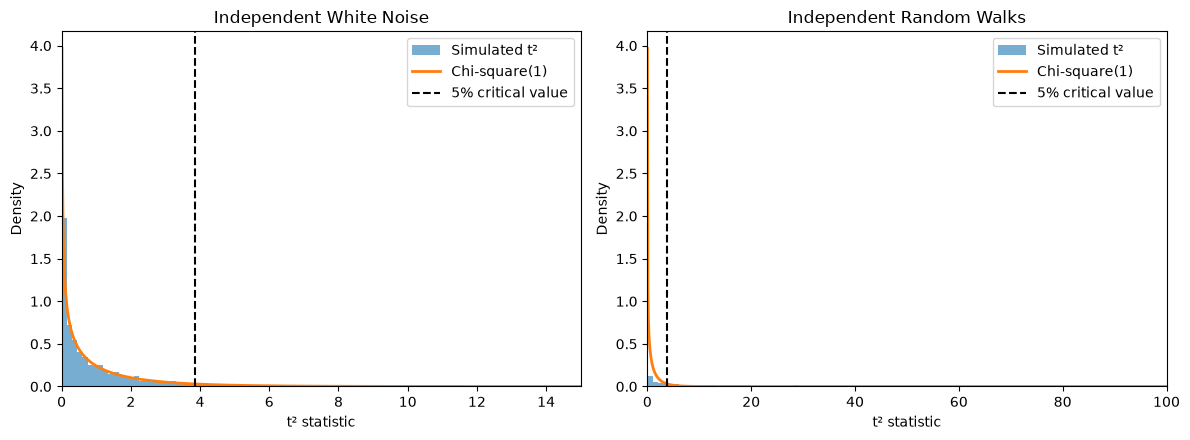

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

rng = np.random.default_rng(2240082)

B = 5000
T = 200
alpha = 0.05


def ols_t_squared(x, y):
    """절편을 포함한 단순회귀의 기울기 t² 계산."""
    xc = x - x.mean(axis=1, keepdims=True)
    yc = y - y.mean(axis=1, keepdims=True)

    sxx = np.sum(xc**2, axis=1)
    beta = np.sum(xc * yc, axis=1) / sxx

    resid = yc - beta[:, None] * xc
    sigma2 = np.sum(resid**2, axis=1) / (T - 2)

    se = np.sqrt(sigma2 / sxx)
    return (beta / se)**2


# 서로 독립인 정규 혁신항
eps = rng.standard_normal((B, T))
eta = rng.standard_normal((B, T))

# Case 1: 독립 백색잡음
stat_white = ols_t_squared(eps, eta)

# Case 2: 독립 랜덤워크
x_rw = np.cumsum(eps, axis=1)
y_rw = np.cumsum(eta, axis=1)

stat_rw = ols_t_squared(x_rw, y_rw)

# 점근적 카이제곱 임계값
critical = chi2.ppf(1 - alpha, df=1)

# 실제 기각률 확인
for name, stat in [
    ("White noise", stat_white),
    ("Random walk", stat_rw),
]:
    rejection_rate = np.mean(stat > critical)
    print(f"{name}: {rejection_rate:.2%}")


# 검정통계량의 분포 비교
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

xmax_list = [15, 100]
stats = [stat_white, stat_rw]
titles = ["Independent White Noise",
          "Independent Random Walks"]

for ax, stat, xmax, title in zip(
    axes, stats, xmax_list, titles
):
    # 공통 bin 폭 사용, 표시 범위 밖은 제외
    bins = np.linspace(0, xmax, 101)
    ax.hist(
        stat, bins=bins, density=True,
        alpha=0.6, label="Simulated t²",
    )

    x = np.linspace(0.01, xmax, 1000)
    ax.plot(
        x, chi2.pdf(x, df=1),
        linewidth=2, label="Chi-square(1)",
    )

    ax.axvline(
        critical, color="black",
        linestyle="--", label="5% critical value",
    )

    ax.set_title(title)
    ax.set_xlabel("t² statistic")
    ax.set_ylabel("Density")
    ax.set_xlim(0, xmax)
    ax.legend()

plt.tight_layout()
plt.show()


C:\Users\noeul\AppData\Local\Temp\ipykernel_28056\2356041690.py:70: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  vp = ax.violinplot(
C:\Users\noeul\AppData\Local\Temp\ipykernel_28056\2356041690.py:93: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(
C:\Users\noeul\AppData\Local\Temp\ipykernel_28056\2356041690.py:70: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  vp = ax.violinplot(
C:\Users\noeul\AppData\Local\Temp\ipykernel_28056\2356041690.py:93: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(


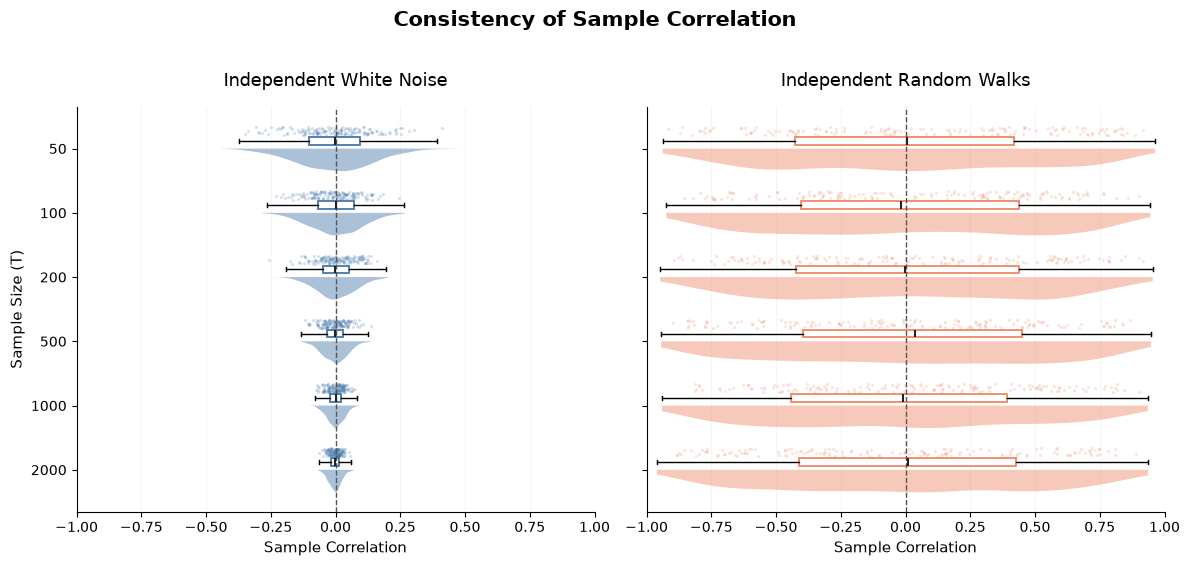

In [7]:

import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Simulation
# --------------------------------------------------
rng = np.random.default_rng(2240082)

B = 1000
T_list = [50, 100, 200, 500, 1000, 2000]

COLORS = {
    "white": "#4477AA",
    "rw": "#EE8866",
}


def sample_corr(x, y):
    xc = x - x.mean(axis=1, keepdims=True)
    yc = y - y.mean(axis=1, keepdims=True)

    numerator = np.sum(xc * yc, axis=1)
    denominator = np.sqrt(
        np.sum(xc**2, axis=1)
        * np.sum(yc**2, axis=1)
    )
    return numerator / denominator


corr_white = []
corr_rw = []

for T in T_list:
    eps = rng.standard_normal((B, T))
    eta = rng.standard_normal((B, T))

    # Independent white noise
    corr_white.append(sample_corr(eps, eta))

    # Independent random walks
    corr_rw.append(
        sample_corr(
            np.cumsum(eps, axis=1),
            np.cumsum(eta, axis=1),
        )
    )


# --------------------------------------------------
# 2. Raincloud Plot
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2, figsize=(12, 5.5),
    sharex=True, sharey=True
)

datasets = [corr_white, corr_rw]
titles = [
    "Independent White Noise",
    "Independent Random Walks",
]
colors = [COLORS["white"], COLORS["rw"]]

positions = np.arange(len(T_list))

for ax, data, title, color in zip(
    axes, datasets, titles, colors
):
    # Half-violin: upper half
    vp = ax.violinplot(
        data,
        positions=positions,
        vert=False,
        widths=0.7,
        showmeans=False,
        showmedians=False,
        showextrema=False,
    )

    for i, body in enumerate(vp["bodies"]):
        vertices = body.get_paths()[0].vertices

        # Keep only the upper half of each violin
        vertices[:, 1] = np.maximum(
            vertices[:, 1], positions[i]
        )

        body.set_facecolor(color)
        body.set_edgecolor("none")
        body.set_alpha(0.45)

    # Boxplot below the violin center
    bp = ax.boxplot(
        data,
        positions=positions - 0.12,
        vert=False,
        widths=0.12,
        patch_artist=True,
        showfliers=False,
        manage_ticks=False,
        medianprops=dict(
            color="#222222", linewidth=1.5
        ),
        boxprops=dict(
            facecolor="white",
            edgecolor=color,
            linewidth=1.3,
        ),
    )

    # Raw observations: small jittered dots
    for i, values in enumerate(data):
        # Subsample for readability
        indices = rng.choice(
            len(values), size=min(150, B),
            replace=False
        )

        jitter = rng.uniform(
            -0.065, 0.065, len(indices)
        )

        ax.scatter(
            values[indices],
            positions[i] - 0.27 + jitter,
            s=5,
            color=color,
            alpha=0.22,
            linewidths=0,
            rasterized=True,
        )

    ax.axvline(
        0, color="#555555",
        linestyle="--", linewidth=1
    )

    ax.set_title(title, fontsize=13, pad=15)
    ax.set_xlabel("Sample Correlation", fontsize=11)
    ax.set_xlim(-1, 1)
    ax.set_ylim(-0.65, len(T_list) - 0.35)
    ax.set_yticks(positions)
    ax.set_yticklabels(T_list)
    ax.grid(axis="x", alpha=0.12)
    ax.spines[["top", "right"]].set_visible(False)

    # Larger sample sizes toward the top
    ax.invert_yaxis()

axes[0].set_ylabel("Sample Size (T)", fontsize=11)

fig.suptitle(
    "Consistency of Sample Correlation",
    fontsize=15, fontweight="bold", y=1.02
)

plt.tight_layout()
plt.savefig(
    "spurious_correlation_raincloud.png",
    dpi=250, bbox_inches="tight"
)
plt.show()


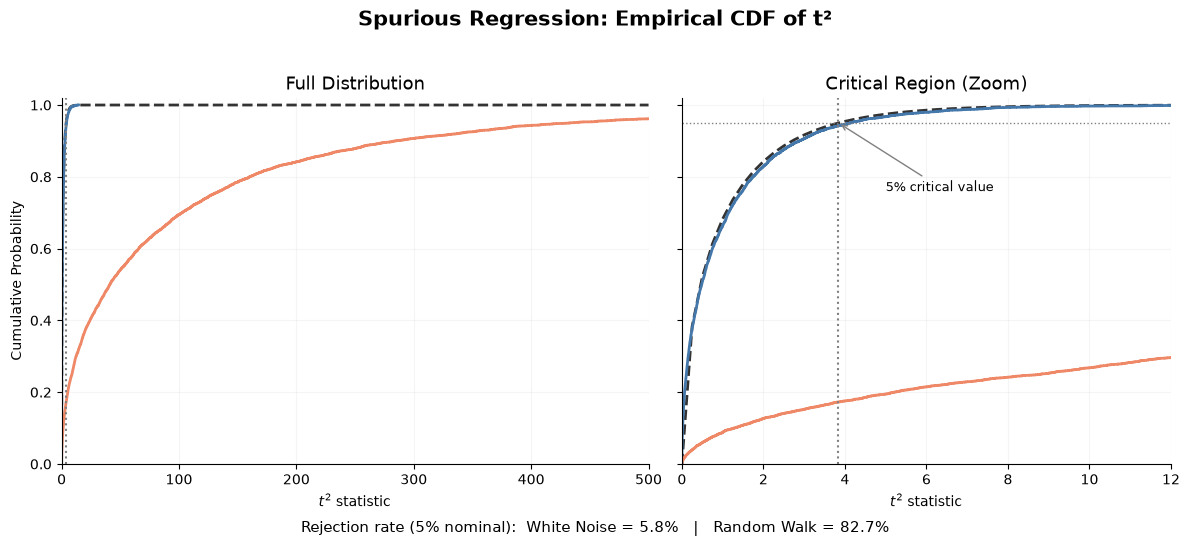

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

# --------------------------------------------------
# 1. Simulation
# --------------------------------------------------
rng = np.random.default_rng(2240082)

B = 5000
T = 200
alpha = 0.05

COLORS = {
    "theory": "#333333",
    "white": "#4477AA",
    "rw": "#A7644E",
}


def ols_t_squared(x, y):
    xc = x - x.mean(axis=1, keepdims=True)
    yc = y - y.mean(axis=1, keepdims=True)

    sxx = np.sum(xc**2, axis=1)
    beta = np.sum(xc * yc, axis=1) / sxx

    resid = yc - beta[:, None] * xc
    sigma2 = np.sum(resid**2, axis=1) / (T - 2)

    se = np.sqrt(sigma2 / sxx)

    return (beta / se)**2


eps = rng.standard_normal((B, T))
eta = rng.standard_normal((B, T))

# Independent white noise
stat_white = ols_t_squared(eps, eta)

# Independent random walks
stat_rw = ols_t_squared(
    np.cumsum(eps, axis=1),
    np.cumsum(eta, axis=1),
)

critical = chi2.ppf(1 - alpha, df=1)

rate_white = np.mean(stat_white > critical)
rate_rw = np.mean(stat_rw > critical)


# --------------------------------------------------
# 2. ECDF Plot
# --------------------------------------------------
def ecdf(values):
    x = np.sort(values)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y


x_white, y_white = ecdf(stat_white)
x_rw, y_rw = ecdf(stat_rw)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5),
    sharey=True,
    gridspec_kw={"width_ratios": [1.2, 1]},
)

for ax in axes:
    x = np.linspace(0, 500, 2000)

    ax.plot(
        x, chi2.cdf(x, df=1),
        color=COLORS["theory"],
        linewidth=2,
        linestyle="--",
        label=r"Theoretical $\chi^2_1$",
    )

    ax.step(
        x_white, y_white,
        where="post",
        color=COLORS["white"],
        linewidth=2,
        label="White Noise",
    )

    ax.step(
        x_rw, y_rw,
        where="post",
        color=COLORS["rw"],
        linewidth=2,
        label="Random Walk",
    )

    ax.axvline(
        critical,
        color="gray",
        linestyle=":",
        linewidth=1.5,
    )

    ax.set_ylim(0, 1.02)
    ax.set_xlabel(r"$t^2$ statistic")
    ax.grid(alpha=0.12)
    ax.spines[["top", "right"]].set_visible(False)

# Full comparison
axes[0].set_xlim(0, 500)
axes[0].set_title("Full Distribution", fontsize=13)
axes[0].set_ylabel("Cumulative Probability")

# Critical region zoom
axes[1].set_xlim(0, 12)
axes[1].set_title("Critical Region (Zoom)", fontsize=13)

axes[1].axhline(
    0.95, color="gray",
    linestyle=":", linewidth=1
)

axes[1].annotate(
    "5% critical value",
    xy=(critical, 0.95),
    xytext=(5, 0.76),
    arrowprops=dict(arrowstyle="->", color="gray"),
    fontsize=9,
)

# Rejection rates
fig.text(
    0.5, -0.015,
    f"Rejection rate (5% nominal):  "
    f"White Noise = {rate_white:.1%}   |   "
    f"Random Walk = {rate_rw:.1%}",
    ha="center",
    fontsize=11,
)

fig.suptitle(
    "Spurious Regression: Empirical CDF of t²",
    fontsize=15, fontweight="bold", y=1.03
)

plt.tight_layout()
plt.savefig(
    "spurious_regression_ecdf.png",
    dpi=250, bbox_inches="tight"
)
plt.show()


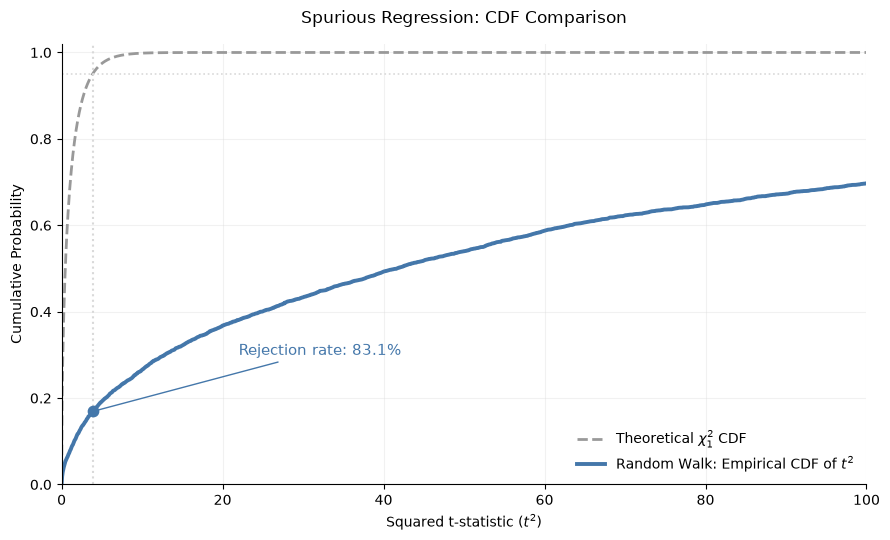

Critical value: 3.841
Rejection rate: 83.10%


: 

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

# --------------------------------------------
# 1. Simulation
# --------------------------------------------
rng = np.random.default_rng(2240082)

B = 5000
T = 200
alpha = 0.05

BLUE = "#4477AA"
GRAY = "#999999"
LIGHT_GRAY = "#D9D9D9"


def ols_t_squared(x, y):
    """OLS with intercept: squared t-statistic."""
    xc = x - x.mean(axis=1, keepdims=True)
    yc = y - y.mean(axis=1, keepdims=True)

    sxx = np.sum(xc**2, axis=1)
    beta = np.sum(xc * yc, axis=1) / sxx

    resid = yc - beta[:, None] * xc
    sigma2 = np.sum(resid**2, axis=1) / (x.shape[1] - 2)

    se = np.sqrt(sigma2 / sxx)
    return (beta / se)**2


def ecdf(values, x):
    sorted_values = np.sort(values)
    return np.searchsorted(
        sorted_values, x, side="right"
    ) / len(sorted_values)


# Independent random walks
eps = rng.standard_normal((B, T))
eta = rng.standard_normal((B, T))

x_rw = np.cumsum(eps, axis=1)
y_rw = np.cumsum(eta, axis=1)

stat_rw = ols_t_squared(x_rw, y_rw)

# --------------------------------------------
# 2. Theoretical CDF vs Empirical CDF
# --------------------------------------------
critical = chi2.ppf(1 - alpha, df=1)

x = np.linspace(0, 100, 1500)

cdf_theory = chi2.cdf(x, df=1)
cdf_rw = ecdf(stat_rw, x)

rejection_rate = np.mean(stat_rw > critical)

# --------------------------------------------
# 3. Visualization
# --------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5.5))

# Theoretical chi-square CDF
ax.plot(
    x, cdf_theory,
    color=GRAY,
    linewidth=2,
    linestyle="--",
    label=r"Theoretical $\chi^2_1$ CDF",
)

# Empirical CDF of squared t-statistics
ax.plot(
    x, cdf_rw,
    color=BLUE,
    linewidth=2.8,
    label=r"Random Walk: Empirical CDF of $t^2$",
)

# Critical value
ax.axvline(
    critical,
    color=LIGHT_GRAY,
    linestyle=":",
    linewidth=1.5,
)

ax.axhline(
    0.95,
    color=LIGHT_GRAY,
    linestyle=":",
    linewidth=1.2,
)

# Empirical CDF at the critical value
cdf_at_critical = 1 - rejection_rate

ax.scatter(
    critical,
    cdf_at_critical,
    color=BLUE,
    s=55,
    zorder=5,
)

ax.annotate(
    f"Rejection rate: {rejection_rate:.1%}",
    xy=(critical, cdf_at_critical),
    xytext=(22, 0.30),
    textcoords="data",
    color=BLUE,
    fontsize=11,
    arrowprops=dict(
        arrowstyle="-",
        color=BLUE,
        linewidth=1,
    ),
)

ax.set_xlim(0, 100)
ax.set_ylim(0, 1.02)

ax.set_xlabel(r"Squared t-statistic ($t^2$)")
ax.set_ylabel("Cumulative Probability")
ax.set_title("Spurious Regression: CDF Comparison", pad=15)

ax.legend(loc="lower right", frameon=False)
ax.grid(color=LIGHT_GRAY, alpha=0.35)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(
    "spurious_regression_cdf.png",
    dpi=250,
    bbox_inches="tight",
)
plt.show()

print(f"Critical value: {critical:.3f}")
print(f"Rejection rate: {rejection_rate:.2%}")
